<a href="https://colab.research.google.com/github/mishra2arya/Unsuppervised-learning/blob/main/RESTAURANT_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv("/content/Zomato Restaurant Dataset.csv")

print(df.head())
print(df.shape)

   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   
3      SM 

In [6]:
X = df.select_dtypes(include=np.number)

print(X.head())

X = X.fillna(X.median())



   Restaurant ID  Country Code   Longitude   Latitude  Average Cost for two  \
0        6317637           162  121.027535  14.565443                  1100   
1        6304287           162  121.014101  14.553708                  1200   
2        6300002           162  121.056831  14.581404                  4000   
3        6318506           162  121.056475  14.585318                  1500   
4        6314302           162  121.057508  14.584450                  1500   

   Price range  Aggregate rating  Votes  
0            3               4.8    314  
1            3               4.5    591  
2            4               4.4    270  
3            4               4.9    365  
4            4               4.8    229  


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print(X_pca)

[[ 2.23172318 -0.76711319]
 [ 2.37813    -0.86783378]
 [ 2.58043954 -0.95928196]
 ...
 [ 3.77772885  0.52398725]
 [ 4.07827639  0.32113664]
 [ 2.8179069   1.06805232]]


In [12]:
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

print(pca_df.head())

        PC1       PC2
0  2.231723 -0.767113
1  2.378130 -0.867834
2  2.580440 -0.959282
3  2.805099 -1.102802
4  2.656507 -1.002590


In [20]:
print(pca.explained_variance_ratio_)

print("Total variance preserved:",
      sum(pca.explained_variance_ratio_))

[0.26640605 0.20427349]
Total variance preserved: 0.4706795438730761


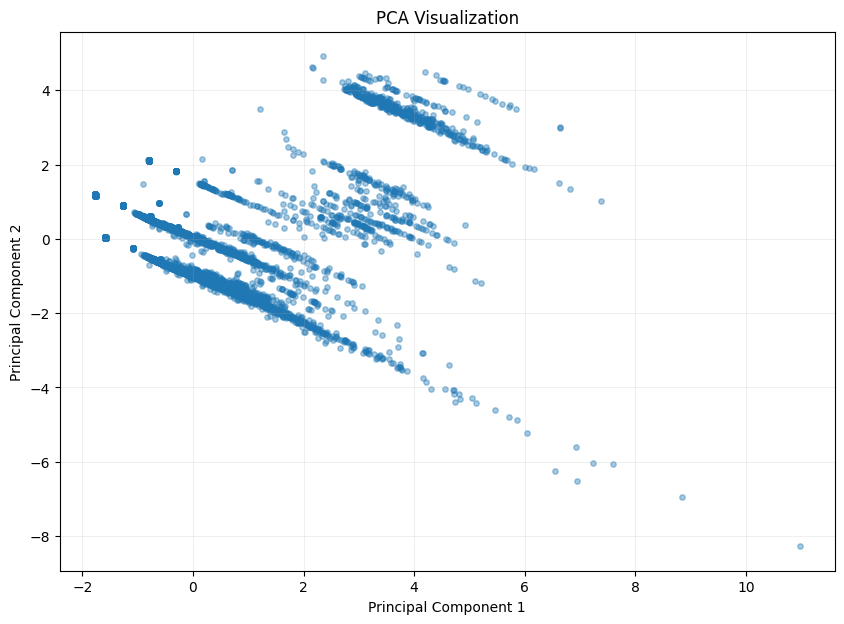

In [21]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    alpha=0.4,
    s=15
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization")

plt.grid(alpha=0.2)
plt.show()

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE

In [23]:
df = pd.read_csv("/content/Zomato Restaurant Dataset.csv")

print(df.head())
print(df.shape)

   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   
3      SM 

In [24]:
X = df.select_dtypes(include=np.number)

# Handle missing values
X = X.fillna(X.median())

In [25]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

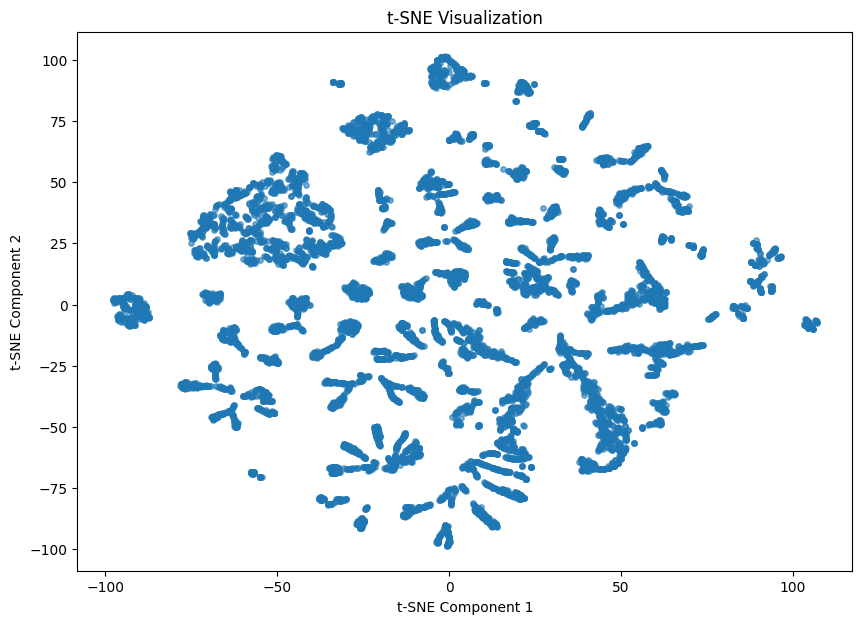

In [30]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    s=15,
    alpha=0.6
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")

plt.title("t-SNE Visualization")

plt.show()

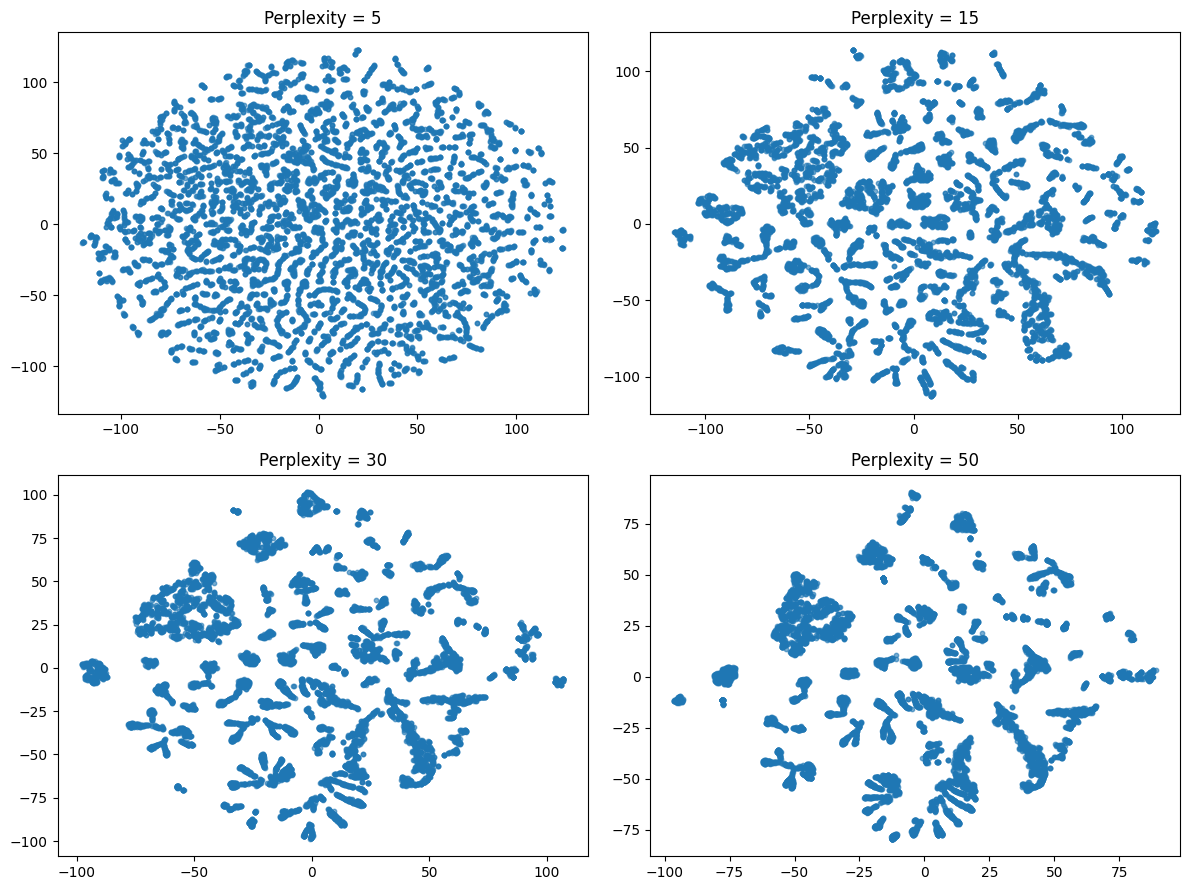

In [29]:
perplexities = [5, 15, 30, 50]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for p, ax in zip(perplexities, axes.flatten()):

    tsne = TSNE(
        n_components=2,
        perplexity=p,
        learning_rate='auto',
        init='pca',
        random_state=42
    )

    result = tsne.fit_transform(X_scaled)

    ax.scatter(
        result[:, 0],
        result[:, 1],
        s=10,
        alpha=0.6
    )

    ax.set_title(f"Perplexity = {p}")

plt.tight_layout()
plt.show()